# Predicting Daily Sales Revenue for Traders in Kejetia Market, Kumasi
### A Linear Regression Case Study (Christ Apostolic University College, Kumasi)




## 0. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")


ImportError: DLL load failed while importing ops_dispatch: An Application Control policy has blocked this file.

## 1. Read the data

The dataset used below, `kumasi_market_traders.csv`, contains **600 simulated
stalls** spread across five sections of Kejetia Market: *Textiles, Foodstuffs,
Electronics, Provisions* and *Footwear*. It was produced by a separate,
standalone script, `generate_kumasi_dataset.py` (provided alongside this
notebook), which encodes realistic assumptions about how each factor should
influence revenue and writes the result out as a CSV file. That generation
script is not part of this notebook — here we simply read in the finished
file, the same way the reference housing notebook reads in `Housing.csv`.

| Column | Meaning |
|---|---|
| `daily_revenue` | Average daily sales (GHS) — **target variable** |
| `foot_traffic_daily` | Estimated number of customers passing the stall per day |
| `stall_size_sqft` | Size of the stall in square feet |
| `years_in_business` | Years the trader has operated in the market |
| `distance_to_entrance_m` | Distance from the stall to the nearest main market entrance (metres) |
| `rain_days_per_week` | Average rainy days per week (rain keeps buyers away / spoils goods) |
| `has_electricity` | Whether the stall has an electricity connection |
| `has_storage` | Whether the trader has extra storage space for stock |
| `near_mainroad` | Whether the stall is near a main road (e.g. the Adum–Kejetia road) |
| `advertises_online` | Whether the trader takes orders via WhatsApp/social media |
| `parking_availability` | Whether customer parking is available nearby |
| `market_section` | Textiles / Foodstuffs / Electronics / Provisions / Footwear |
| `trader_age_years` | Trader's age (included deliberately — see note below) |
| `uses_mobile_money` | Whether the trader accepts Mobile Money (included deliberately) |

`trader_age_years` and `uses_mobile_money` were added to the dataset on
purpose even though they do **not** genuinely drive revenue in the
generation script. They exist to test whether the feature-selection steps
below (RFE, p-values) correctly identify them as unhelpful, the same way a
real trader survey would contain some irrelevant questions.


In [ ]:
df = pd.read_csv('kumasi_market_traders.csv')
df.head()


,daily_revenue,foot_traffic_daily,stall_size_sqft,years_in_business,distance_to_entrance_m,rain_days_per_week,trader_age_years,has_electricity,has_storage,near_mainroad,advertises_online,parking_availability,market_section,uses_mobile_money
0,500.29,255,23.2,1.2,194,2,38,yes,yes,no,yes,no,Foodstuffs,no
1,529.03,222,20.9,1.6,5,4,40,yes,yes,yes,no,no,Footwear,no
2,438.46,274,27.0,21.3,212,0,44,no,no,yes,no,no,Provisions,yes
3,742.02,267,18.7,1.2,165,6,31,yes,yes,yes,no,yes,Electronics,no
4,212.80,192,23.0,11.6,133,2,51,no,no,no,no,no,Textiles,no


**View the number of rows and columns in the data**

In [ ]:
df.shape   # (rows, columns)


(600, 14)

**View summary statistics of the numerical columns**

In [ ]:
df.describe()


,daily_revenue,foot_traffic_daily,stall_size_sqft,years_in_business,distance_to_entrance_m,rain_days_per_week,trader_age_years
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,475.124083,223.201667,28.459500,6.029500,182.276667,1.991667,37.848333
std,162.905546,77.991017,8.808088,6.102862,93.414920,1.352027,9.848027
min,55.000000,20.000000,8.000000,0.000000,5.000000,0.000000,18.000000
25%,366.592500,168.000000,22.675000,1.700000,117.750000,1.000000,31.000000
50%,469.350000,224.000000,28.300000,4.300000,178.000000,2.000000,38.000000
75%,578.387500,275.000000,33.950000,8.000000,246.250000,3.000000,45.000000
max,996.880000,469.000000,55.700000,35.000000,499.000000,6.000000,68.000000


**Column data types and non-null counts**

In [ ]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   daily_revenue           600 non-null    float64
 1   foot_traffic_daily      600 non-null    int64  
 2   stall_size_sqft         600 non-null    float64
 3   years_in_business       600 non-null    float64
 4   distance_to_entrance_m  600 non-null    int64  
 5   rain_days_per_week      600 non-null    int64  
 6   trader_age_years        600 non-null    int64  
 7   has_electricity         600 non-null    str    
 8   has_storage             600 non-null    str    
 9   near_mainroad           600 non-null    str    
 10  advertises_online       600 non-null    str    
 11  parking_availability    600 non-null    str    
 12  market_section          600 non-null    str    
 13  uses_mobile_money       600 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 65.8 KB

**Look for duplicate rows in the dataset**

In [ ]:
df.loc[df.duplicated()]


,daily_revenue,foot_traffic_daily,stall_size_sqft,years_in_business,distance_to_entrance_m,rain_days_per_week,trader_age_years,has_electricity,has_storage,near_mainroad,advertises_online,parking_availability,market_section,uses_mobile_money


No duplicate rows.

**Get the names of the columns**

In [ ]:
df.columns


Index(['daily_revenue', 'foot_traffic_daily', 'stall_size_sqft',
       'years_in_business', 'distance_to_entrance_m', 'rain_days_per_week',
       'trader_age_years', 'has_electricity', 'has_storage', 'near_mainroad',
       'advertises_online', 'parking_availability', 'market_section',
       'uses_mobile_money'],
      dtype='str')

**Check for missing values**

In [ ]:
df.isna().sum()


daily_revenue             0
foot_traffic_daily        0
stall_size_sqft           0
years_in_business         0
distance_to_entrance_m    0
rain_days_per_week        0
trader_age_years          0
has_electricity           0
has_storage               0
near_mainroad             0
advertises_online         0
parking_availability      0
market_section            0
uses_mobile_money         0
dtype: int64

No missing values.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Distribution of the target variable, `daily_revenue`

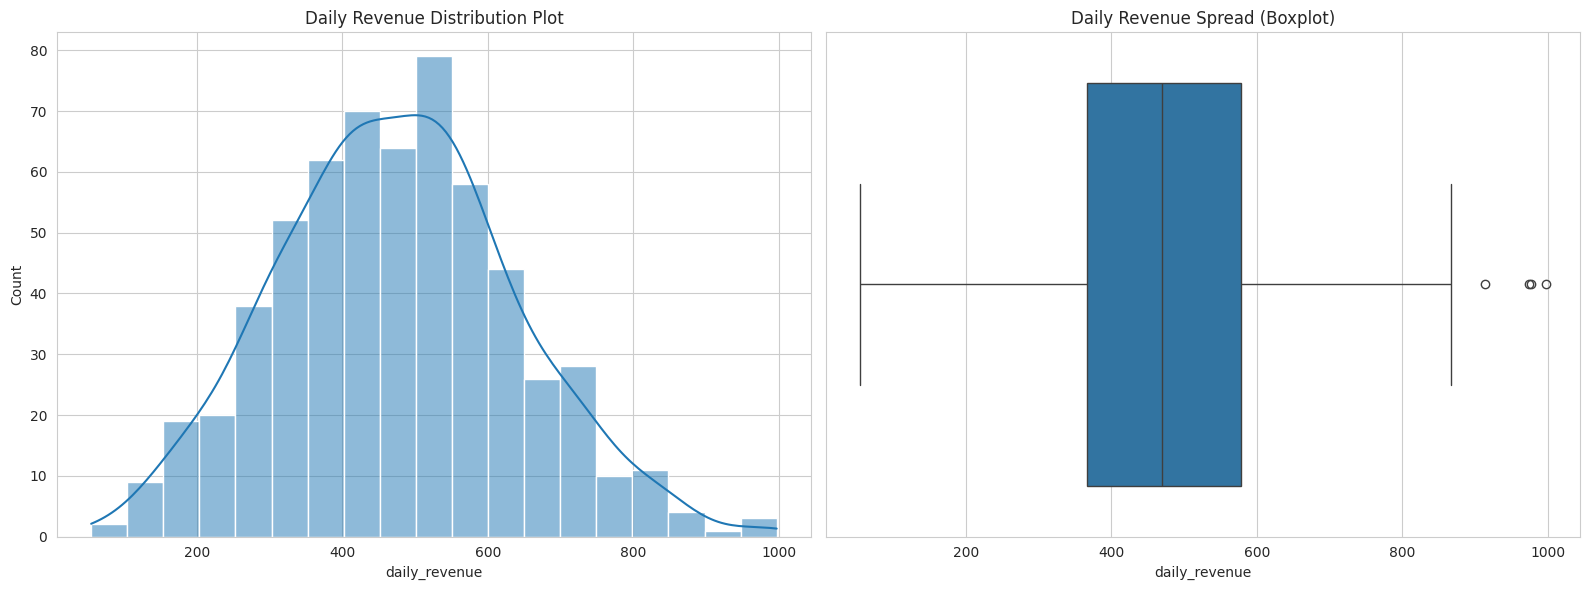

In [ ]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.title('Daily Revenue Distribution Plot')
sns.histplot(df.daily_revenue, kde=True)

plt.subplot(1, 2, 2)
plt.title('Daily Revenue Spread (Boxplot)')
sns.boxplot(x=df.daily_revenue)

plt.tight_layout()
plt.show()


In [ ]:
print(df.daily_revenue.describe(percentiles=[0.25, 0.50, 0.75, 0.85, 0.90, 1]))


count    600.000000
mean     475.124083
std      162.905546
min       55.000000
25%      366.592500
50%      469.350000
75%      578.387500
85%      639.981500
90%      689.954000
100%     996.880000
max      996.880000
Name: daily_revenue, dtype: float64


**Inference:** the distribution of `daily_revenue` is roughly bell-shaped with a
mild right skew — a small number of high-earning stalls (mostly Electronics)
pull the mean slightly above the median.


### 2.2 Visualising categorical (yes/no) attributes

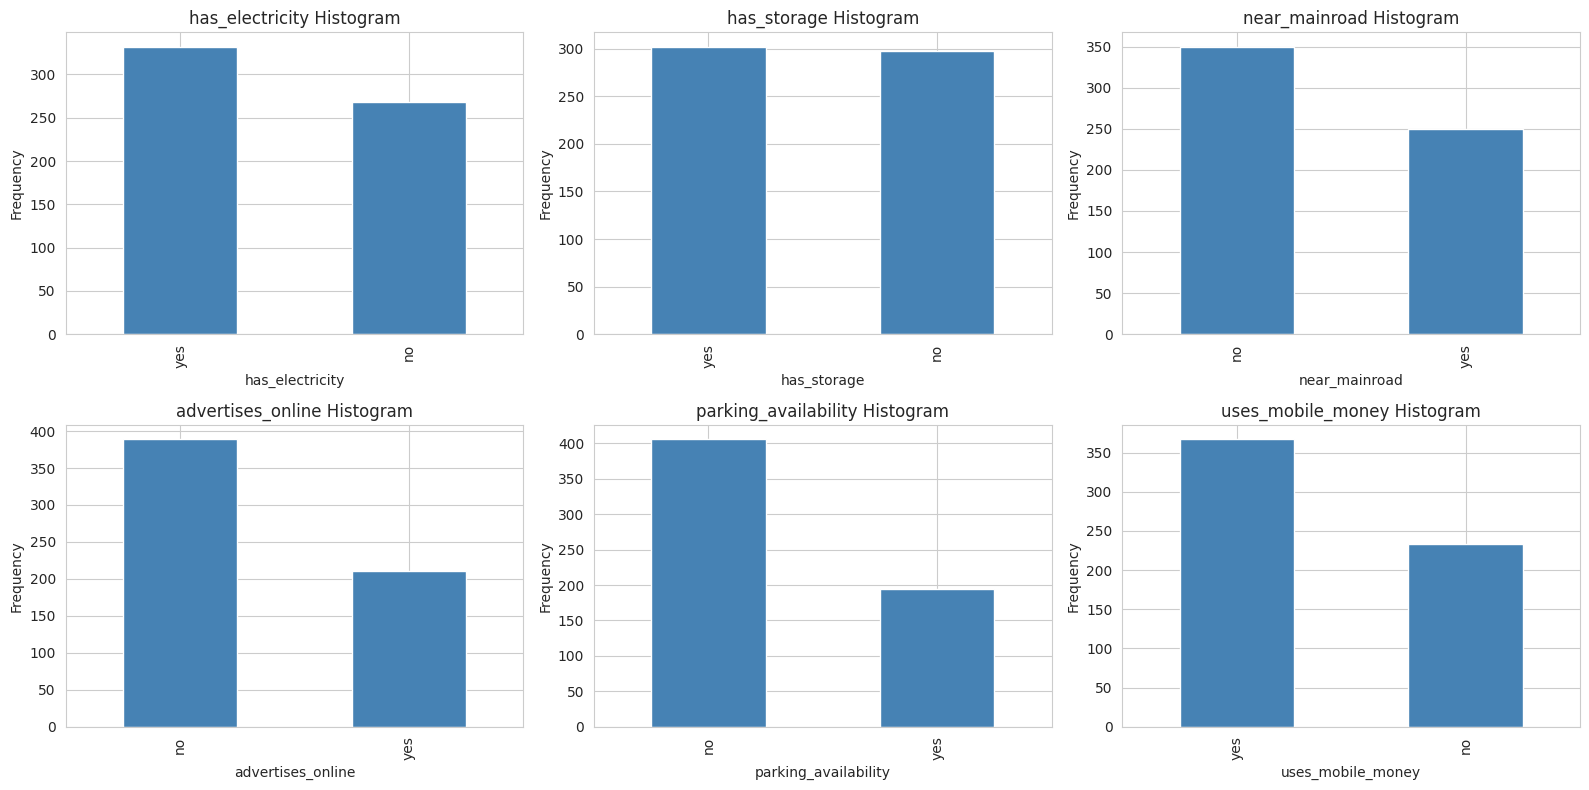

In [ ]:
binary_cols = ['has_electricity', 'has_storage', 'near_mainroad',
               'advertises_online', 'parking_availability', 'uses_mobile_money']

plt.figure(figsize=(16, 8))
for i, col in enumerate(binary_cols, start=1):
    plt.subplot(2, 3, i)
    ax = df[col].value_counts().plot(kind='bar', color='steelblue')
    plt.title(f'{col} Histogram')
    ax.set(xlabel=col, ylabel='Frequency')
plt.tight_layout()
plt.show()


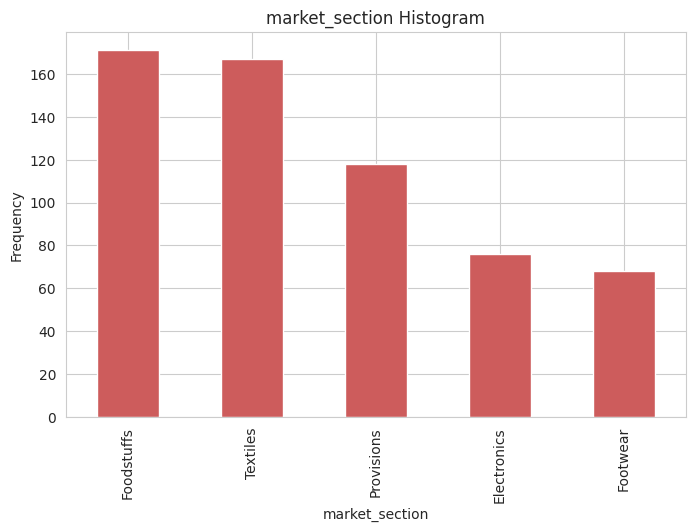

In [ ]:
plt.figure(figsize=(8, 5))
ax = df['market_section'].value_counts().plot(kind='bar', color='indianred')
plt.title('market_section Histogram')
ax.set(xlabel='market_section', ylabel='Frequency')
plt.show()


### 2.3 Categorical attributes vs. `daily_revenue`

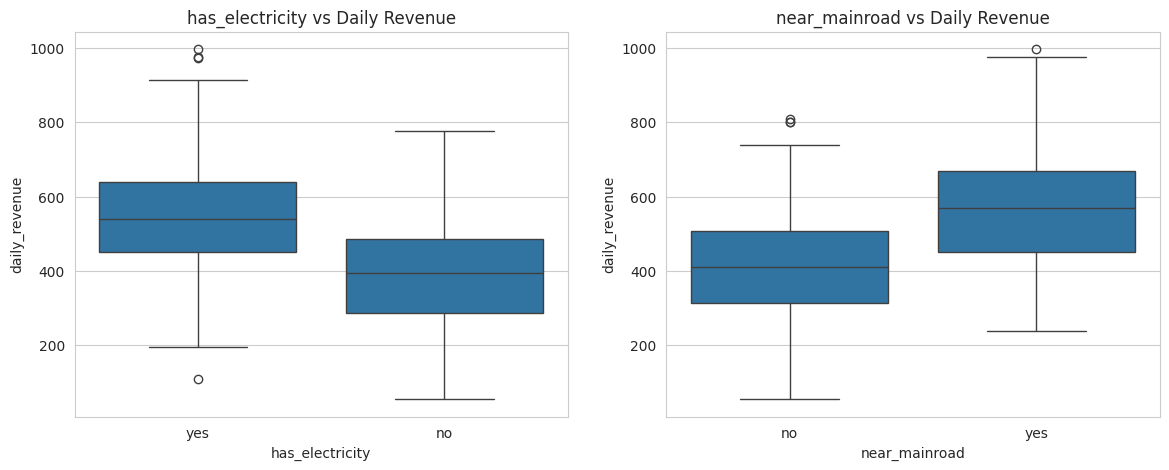

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.title('has_electricity vs Daily Revenue')
sns.boxplot(x=df.has_electricity, y=df.daily_revenue)

plt.subplot(1, 2, 2)
plt.title('near_mainroad vs Daily Revenue')
sns.boxplot(x=df.near_mainroad, y=df.daily_revenue)

plt.show()


**Inference:** having electricity and being near the main road both line up with clearly higher daily revenue.

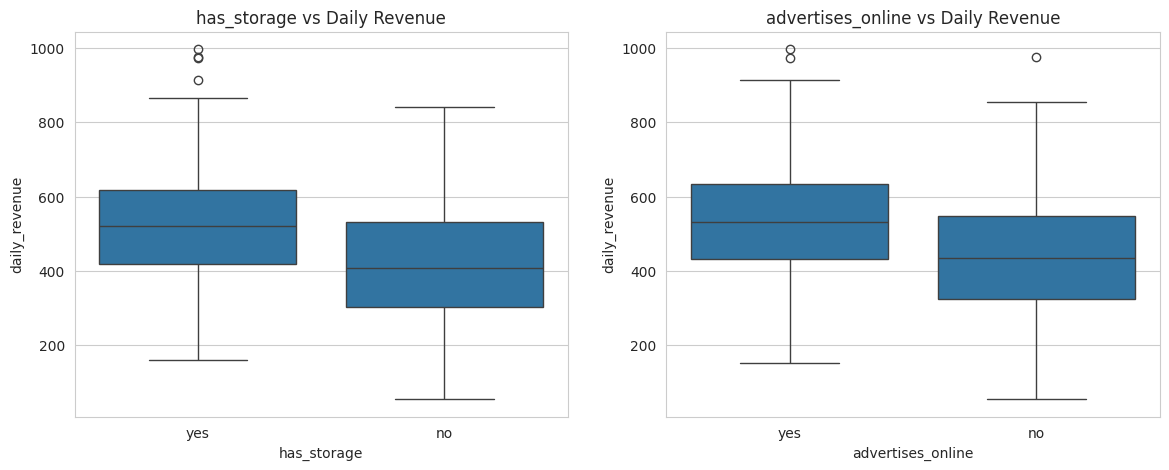

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.title('has_storage vs Daily Revenue')
sns.boxplot(x=df.has_storage, y=df.daily_revenue)

plt.subplot(1, 2, 2)
plt.title('advertises_online vs Daily Revenue')
sns.boxplot(x=df.advertises_online, y=df.daily_revenue)

plt.show()


**Inference:** storage space and online advertising (WhatsApp/social media orders) both show a modest positive association with revenue.

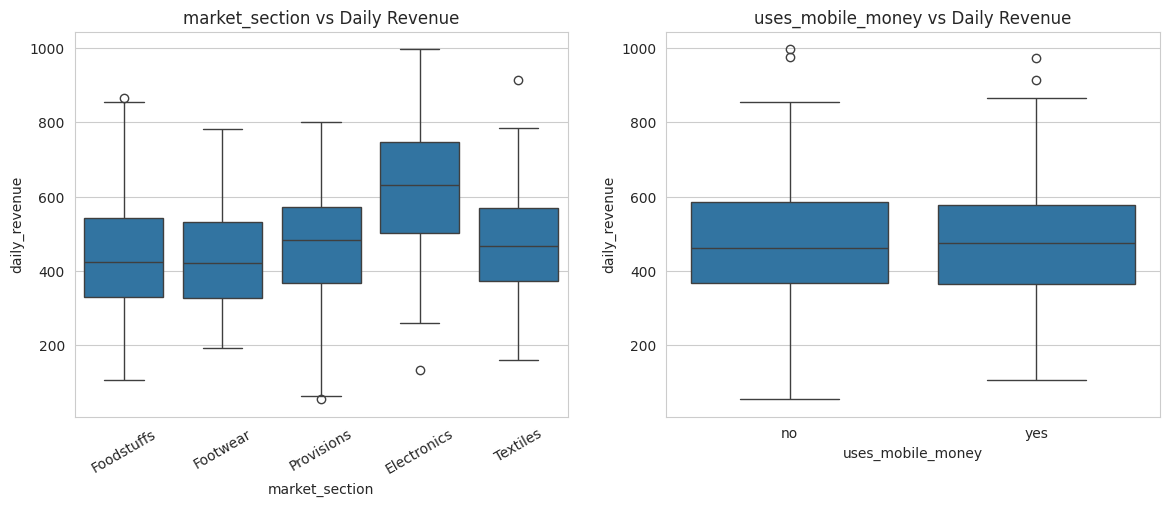

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.title('market_section vs Daily Revenue')
sns.boxplot(x=df.market_section, y=df.daily_revenue)
plt.xticks(rotation=30)

plt.subplot(1, 2, 2)
plt.title('uses_mobile_money vs Daily Revenue')
sns.boxplot(x=df.uses_mobile_money, y=df.daily_revenue)

plt.show()


**Inference:** Electronics stalls earn noticeably more than the other
sections. `uses_mobile_money`, on the other hand, shows almost no visible
difference between "yes" and "no" — a first hint that it may not be a useful
predictor, which the modelling steps below will test formally.


### 2.4 Visualising numerical attributes

In [ ]:
numerical_list = [x for x in df.columns if df[x].dtype in ('int64', 'float64')]
print(numerical_list)


['daily_revenue', 'foot_traffic_daily', 'stall_size_sqft', 'years_in_business', 'distance_to_entrance_m', 'rain_days_per_week', 'trader_age_years']


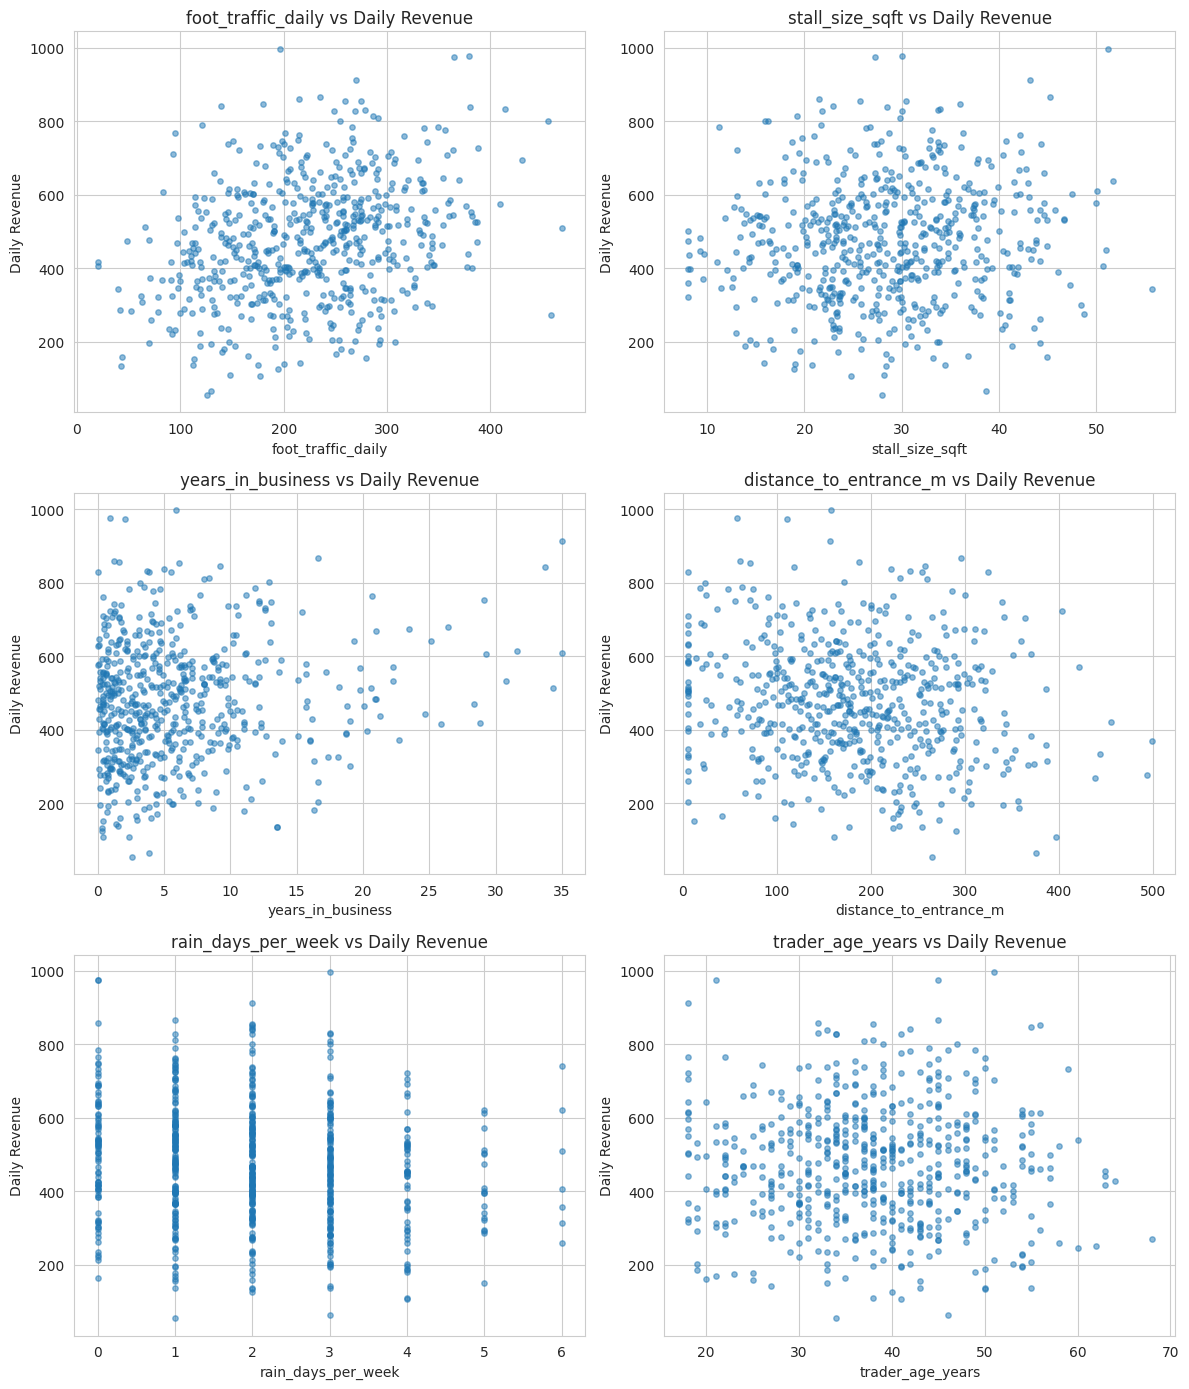

In [ ]:
def scatter(x, fig):
    plt.subplot(3, 2, fig)
    plt.scatter(df[x], df['daily_revenue'], alpha=0.5, s=15)
    plt.title(x + ' vs Daily Revenue')
    plt.ylabel('Daily Revenue')
    plt.xlabel(x)

plt.figure(figsize=(12, 14))
scatter('foot_traffic_daily', 1)
scatter('stall_size_sqft', 2)
scatter('years_in_business', 3)
scatter('distance_to_entrance_m', 4)
scatter('rain_days_per_week', 5)
scatter('trader_age_years', 6)
plt.tight_layout()
plt.show()


**Inference:** `foot_traffic_daily` and `years_in_business` show a clear
positive trend with revenue; `distance_to_entrance_m` and `rain_days_per_week`
show a negative trend. `trader_age_years` shows no visible pattern at all —
another sign that it is not a genuine driver of revenue.


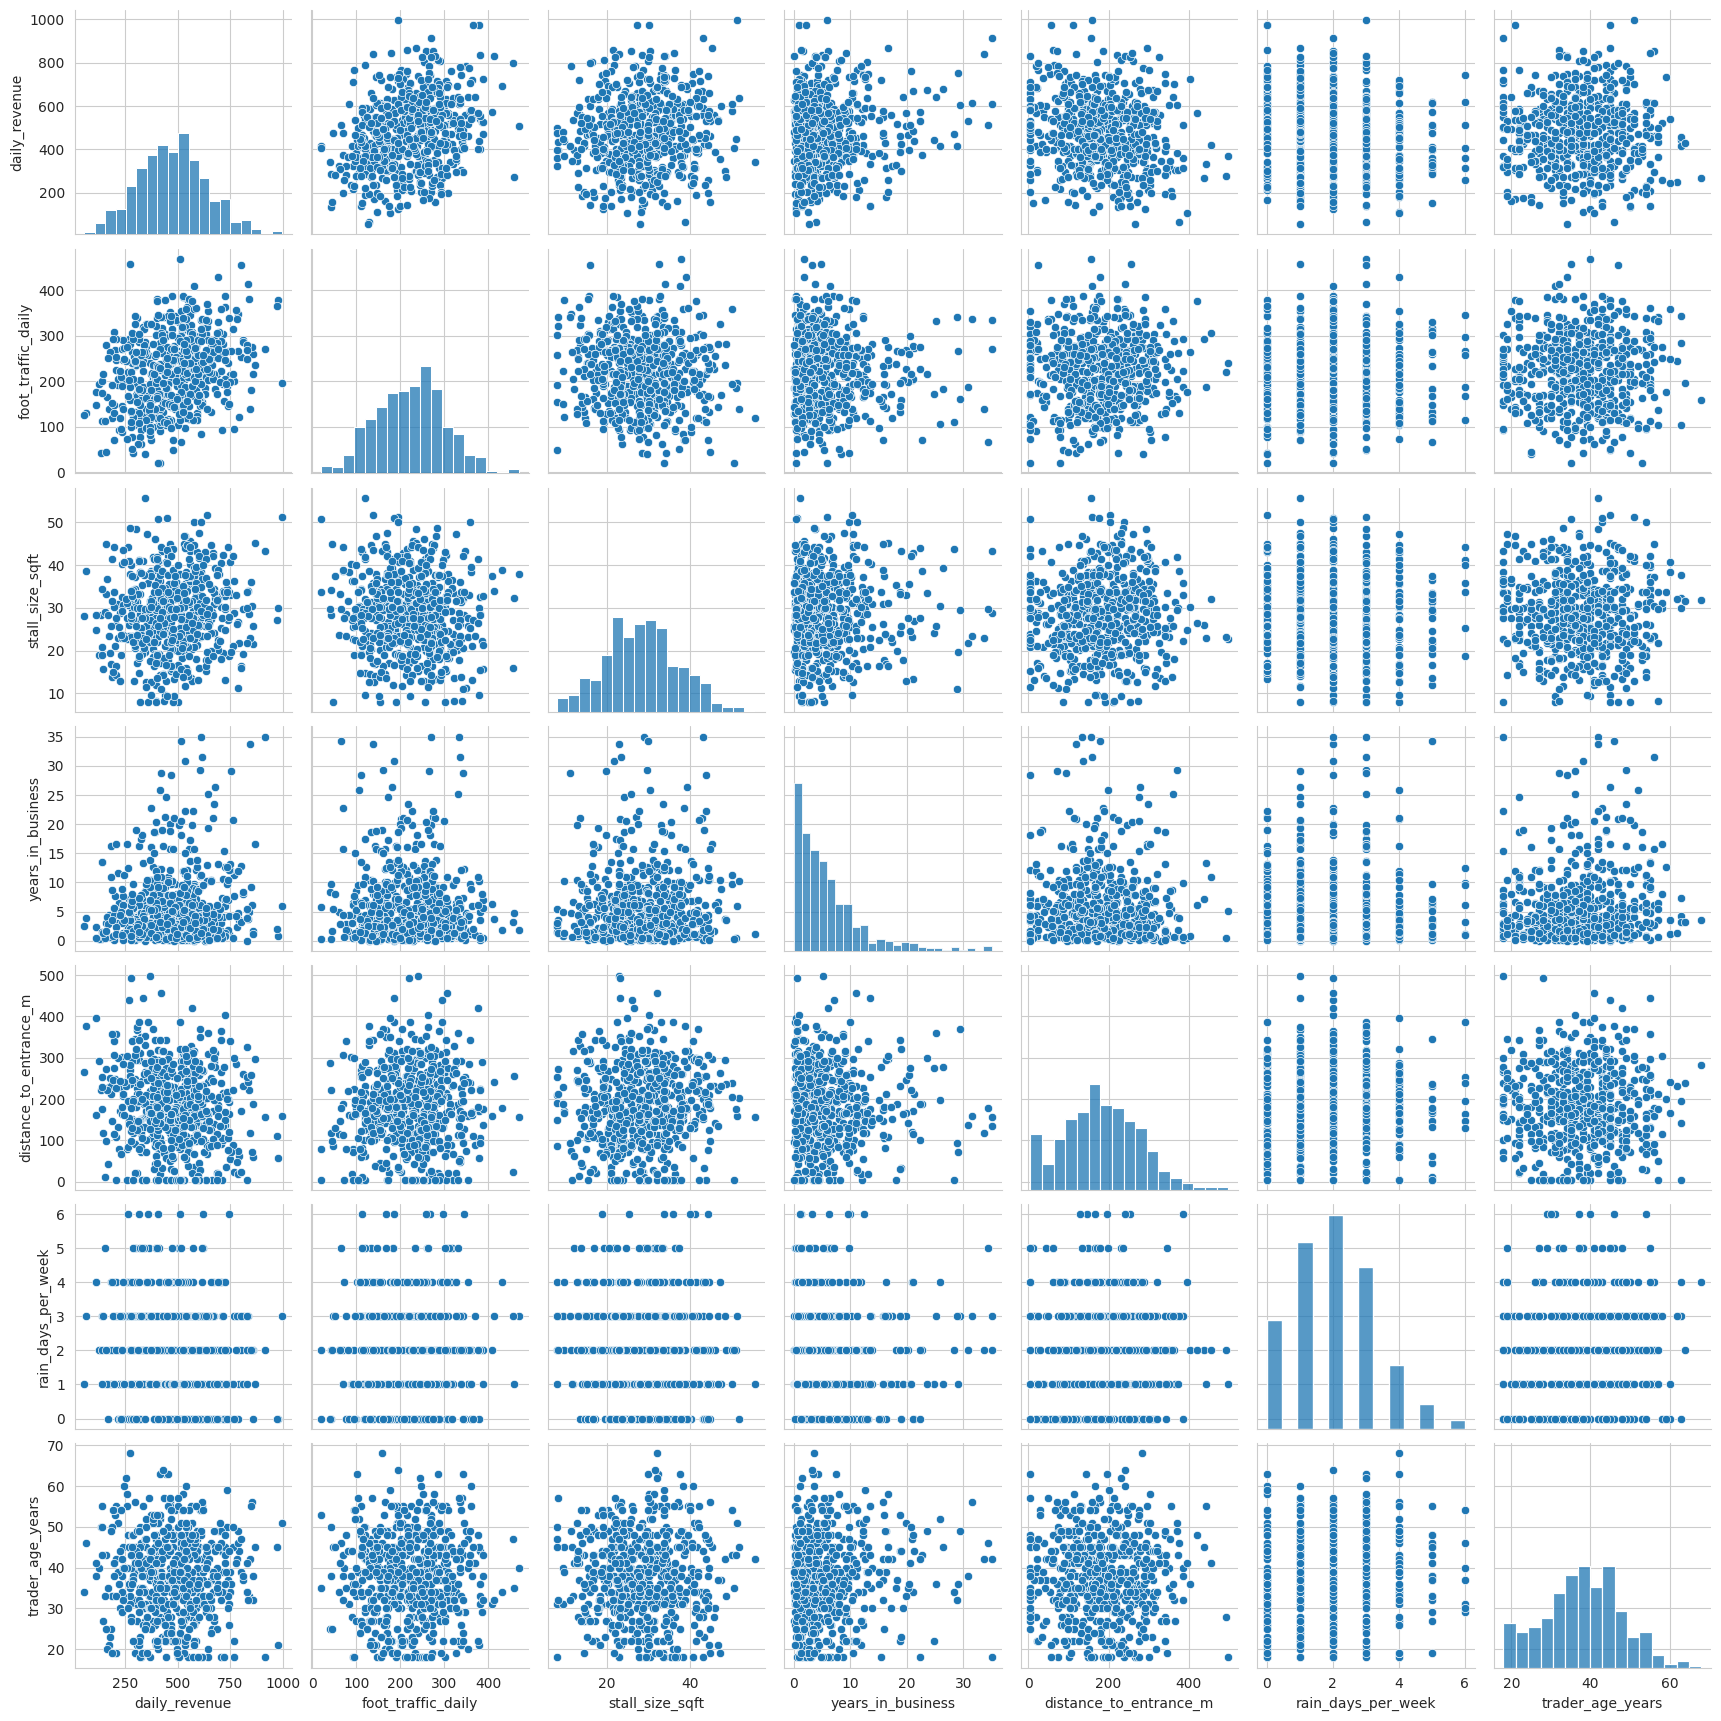

In [ ]:
sns.pairplot(df[numerical_list])
plt.show()


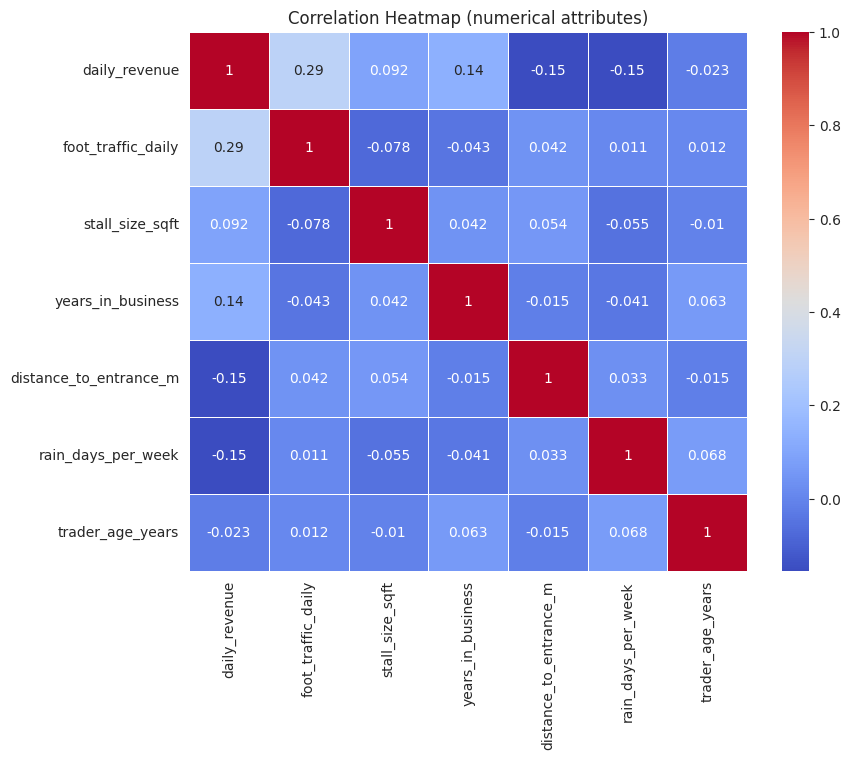

In [ ]:
cor_matrix = df[numerical_list].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(cor_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap (numerical attributes)')
plt.show()


## 3. Creating dummy variables

Linear regression needs numbers, not text categories, so every `yes`/`no`
column and the `market_section` column are converted into 0/1 **dummy
variables** with `pd.get_dummies(..., drop_first=True)`. `drop_first=True`
drops one category as the baseline (e.g. `no` for a yes/no column) to avoid
duplicating information. The dummy columns are explicitly prefixed with the
original column name (`has_electricity_yes`, `market_section_Textiles`, …) so
that, unlike a plain `get_dummies` call, every dummy column keeps a unique,
self-explanatory name.


In [ ]:
def dummies(x, df):
    temp = pd.get_dummies(df[x], drop_first=True, prefix=x).astype(int)
    df = pd.concat([df, temp], axis=1)
    df.drop([x], axis=1, inplace=True)
    return df

df_model = df.copy()
for col in ['has_electricity', 'has_storage', 'near_mainroad', 'advertises_online',
            'parking_availability', 'uses_mobile_money', 'market_section']:
    df_model = dummies(col, df_model)

df_model.head()


,daily_revenue,foot_traffic_daily,stall_size_sqft,years_in_business,distance_to_entrance_m,rain_days_per_week,trader_age_years,has_electricity_yes,has_storage_yes,near_mainroad_yes,advertises_online_yes,parking_availability_yes,uses_mobile_money_yes,market_section_Foodstuffs,market_section_Footwear,market_section_Provisions,market_section_Textiles
0,500.29,255,23.2,1.2,194,2,38,1,1,0,1,0,0,1,0,0,0
1,529.03,222,20.9,1.6,5,4,40,1,1,1,0,0,0,0,1,0,0
2,438.46,274,27.0,21.3,212,0,44,0,0,1,0,0,1,0,0,1,0
3,742.02,267,18.7,1.2,165,6,31,1,1,1,0,1,0,0,0,0,0
4,212.80,192,23.0,11.6,133,2,51,0,0,0,0,0,0,0,0,0,1


In [ ]:
df_model.shape


(600, 17)

## 4. Train/test split and scaling

In [ ]:
from sklearn.model_selection import train_test_split

np.random.seed(0)
df_train, df_test = train_test_split(df_model, train_size=0.75, test_size=0.25,
                                      random_state=100)
print(df_train.shape, df_test.shape)


(450, 17) (150, 17)


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Fit the scaler ONLY on the training data, then apply the same scaling to the
# test data with .transform() (not .fit_transform()). This avoids "leaking"
# information about the test set into the scaler, which is a common mistake.
df_train[numerical_list] = scaler.fit_transform(df_train[numerical_list])
df_test[numerical_list]  = scaler.transform(df_test[numerical_list])

df_train.head()


,daily_revenue,foot_traffic_daily,stall_size_sqft,years_in_business,distance_to_entrance_m,rain_days_per_week,trader_age_years,has_electricity_yes,has_storage_yes,near_mainroad_yes,advertises_online_yes,parking_availability_yes,uses_mobile_money_yes,market_section_Foodstuffs,market_section_Footwear,market_section_Provisions,market_section_Textiles
259,0.542755,0.630290,0.494759,0.131429,0.625506,0.333333,0.32,0,0,1,1,0,1,0,0,0,1
353,0.285822,0.309577,0.329140,0.022857,0.234818,0.333333,0.56,1,1,0,0,0,0,0,0,0,1
363,0.463276,0.701559,0.587002,0.168571,0.331984,0.500000,0.42,1,0,0,1,0,0,1,0,0,0
221,0.155529,0.554566,0.272537,0.217143,0.491903,0.500000,0.70,0,0,0,0,0,0,1,0,0,0
443,0.574012,0.436526,0.446541,0.248571,0.392713,0.166667,0.00,1,0,1,0,0,0,1,0,0,0


In [ ]:
# Split each set into predictors (X) and the target (y)
y_train = df_train.pop('daily_revenue')
X_train = df_train

y_test = df_test.pop('daily_revenue')
X_test = df_test


## 5. Feature selection with Recursive Feature Elimination (RFE)

`X_train` has 16 candidate predictor columns (after dummy encoding). RFE
repeatedly fits a linear regression, removes the weakest predictor, and
refits, until only the requested number of predictors remain. We ask it to
keep the best **14**, leaving 2 out.


In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

rfe = RFE(estimator=LinearRegression(), n_features_to_select=14)
rfe = rfe.fit(X_train, y_train)

list(zip(X_train.columns, rfe.support_, rfe.ranking_))


[('foot_traffic_daily', np.True_, np.int64(1)),
 ('stall_size_sqft', np.True_, np.int64(1)),
 ('years_in_business', np.True_, np.int64(1)),
 ('distance_to_entrance_m', np.True_, np.int64(1)),
 ('rain_days_per_week', np.True_, np.int64(1)),
 ('trader_age_years', np.False_, np.int64(3)),
 ('has_electricity_yes', np.True_, np.int64(1)),
 ('has_storage_yes', np.True_, np.int64(1)),
 ('near_mainroad_yes', np.True_, np.int64(1)),
 ('advertises_online_yes', np.True_, np.int64(1)),
 ('parking_availability_yes', np.True_, np.int64(1)),
 ('uses_mobile_money_yes', np.False_, np.int64(2)),
 ('market_section_Foodstuffs', np.True_, np.int64(1)),
 ('market_section_Footwear', np.True_, np.int64(1)),
 ('market_section_Provisions', np.True_, np.int64(1)),
 ('market_section_Textiles', np.True_, np.int64(1))]

`rfe.support_` is `True` for a kept feature and `False` for a dropped one.
Encouragingly, RFE drops exactly the two attributes that were deliberately
left out of the true revenue formula: `trader_age_years` and
`uses_mobile_money_yes`. This is good evidence that the feature-selection step
is working correctly rather than picking columns at random.


In [ ]:
X_train.columns[rfe.support_]


Index(['foot_traffic_daily', 'stall_size_sqft', 'years_in_business',
       'distance_to_entrance_m', 'rain_days_per_week', 'has_electricity_yes',
       'has_storage_yes', 'near_mainroad_yes', 'advertises_online_yes',
       'parking_availability_yes', 'market_section_Foodstuffs',
       'market_section_Footwear', 'market_section_Provisions',
       'market_section_Textiles'],
      dtype='str')

In [ ]:
X_train_rfe = X_train[X_train.columns[rfe.support_]]
X_train_rfe.head()


,foot_traffic_daily,stall_size_sqft,years_in_business,distance_to_entrance_m,rain_days_per_week,has_electricity_yes,has_storage_yes,near_mainroad_yes,advertises_online_yes,parking_availability_yes,market_section_Foodstuffs,market_section_Footwear,market_section_Provisions,market_section_Textiles
259,0.630290,0.494759,0.131429,0.625506,0.333333,0,0,1,1,0,0,0,0,1
353,0.309577,0.329140,0.022857,0.234818,0.333333,1,1,0,0,0,0,0,0,1
363,0.701559,0.587002,0.168571,0.331984,0.500000,1,0,0,1,0,1,0,0,0
221,0.554566,0.272537,0.217143,0.491903,0.500000,0,0,0,0,0,1,0,0,0
443,0.436526,0.446541,0.248571,0.392713,0.166667,1,0,1,0,0,1,0,0,0


## 6. Building the OLS regression model

In [ ]:
def build_model(X, y):
    X = sm.add_constant(X)      # adds an intercept term
    lm = sm.OLS(y, X).fit()     # ordinary least squares fit
    print(lm.summary())
    return X, lm

def checkVIF(X):
    vif = pd.DataFrame()
    vif['Features'] = X.columns
    vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    vif['VIF'] = round(vif['VIF'], 2)
    return vif.sort_values(by='VIF', ascending=False)


### Model 1 (all 14 RFE-selected features)

In [ ]:
X_train_model, lm = build_model(X_train_rfe, y_train)


                            OLS Regression Results                            
Dep. Variable:          daily_revenue   R-squared:                       0.953
Model:                            OLS   Adj. R-squared:                  0.952
Method:                 Least Squares   F-statistic:                     634.6
Date:                Fri, 25 Sep 2026   Prob (F-statistic):          4.14e-279
Time:                        00:54:13   Log-Likelihood:                 839.39
No. Observations:                 450   AIC:                            -1649.
Df Residuals:                     435   BIC:                            -1587.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [ ]:
checkVIF(X_train_model)


,Features,VIF
11,market_section_Foodstuffs,2.39
14,market_section_Textiles,2.29
13,market_section_Provisions,2.03
12,market_section_Footwear,1.76
1,foot_traffic_daily,1.04
2,stall_size_sqft,1.04
6,has_electricity_yes,1.03
8,near_mainroad_yes,1.03
9,advertises_online_yes,1.03
7,has_storage_yes,1.03


**Reading the results:**
- Every predictor has a p-value of **0.000** (< 0.05), so all 14 kept
  features are statistically significant — none needs to be dropped for
  being insignificant, unlike in some datasets where a weak predictor slips
  through RFE.
- Every VIF is **below 3** (well under the usual concern threshold of 5–10),
  so multicollinearity is not a problem for this feature set.
- Adjusted R-squared is very high because the synthetic data was generated
  from a known linear rule with modest random noise added — in a real survey
  of Kejetia traders, an R-squared this high would be unusual and a lower
  value (e.g. 0.5–0.7, as in typical market/sales survey data) would be
  perfectly normal.

Because no feature needs to be removed on either ground, **Model 1 is our
final model** — there is no need for a Model 2 / Model 3 refinement round
here.


## 7. Residual analysis

A key assumption of linear regression is that the residuals (errors) are
roughly normally distributed and centred on zero.


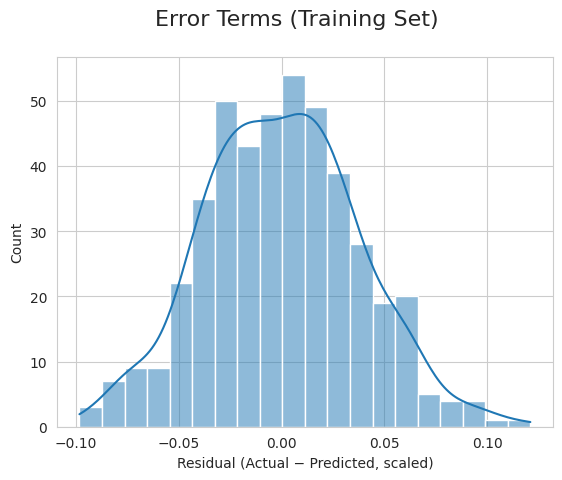

In [ ]:
y_train_pred = lm.predict(X_train_model)

fig = plt.figure()
sns.histplot((y_train - y_train_pred), bins=20, kde=True)
fig.suptitle('Error Terms (Training Set)', fontsize=16)
plt.xlabel('Residual (Actual − Predicted, scaled)')
plt.show()


**Inference:** the residuals are approximately normally distributed and centred near zero, so this assumption of linear regression is satisfied.

## 8. Predicting on the test set (unseen data)

In [ ]:
# Keep only the columns the final model uses, in the same order, then add the constant
final_features = [c for c in X_train_model.columns if c != 'const']
X_test_model = X_test[final_features]
X_test_model = sm.add_constant(X_test_model)
X_test_model = X_test_model[X_train_model.columns]   # match column order exactly

y_pred = lm.predict(X_test_model)


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error

print("R-squared on test set:", round(r2_score(y_test, y_pred), 4))
print("Mean Absolute Error (scaled 0-1 units):", round(mean_absolute_error(y_test, y_pred), 4))


R-squared on test set: 0.9498
Mean Absolute Error (scaled 0-1 units): 0.0299


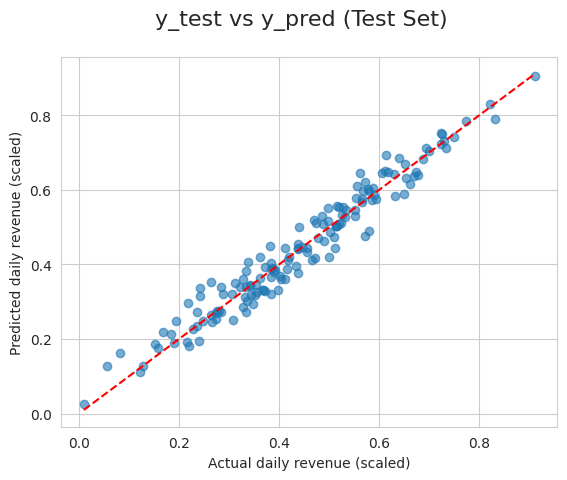

In [ ]:
fig = plt.figure()
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
fig.suptitle('y_test vs y_pred (Test Set)', fontsize=16)
plt.xlabel('Actual daily revenue (scaled)')
plt.ylabel('Predicted daily revenue (scaled)')
plt.show()


In [ ]:
print(lm.summary())


                            OLS Regression Results                            
Dep. Variable:          daily_revenue   R-squared:                       0.953
Model:                            OLS   Adj. R-squared:                  0.952
Method:                 Least Squares   F-statistic:                     634.6
Date:                Fri, 25 Sep 2026   Prob (F-statistic):          4.14e-279
Time:                        00:54:13   Log-Likelihood:                 839.39
No. Observations:                 450   AIC:                            -1649.
Df Residuals:                     435   BIC:                            -1587.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

**Inference:** the model explains the large majority of the variation in
test-set revenue and points fall close to the red diagonal (perfect
prediction) line, so the model generalises well to stalls it was not trained
on. In practice this model suggests that, for Kejetia traders, **foot
traffic, years in business, proximity to the main road, having electricity,
and choice of market section** are the strongest drivers of daily revenue,
while a trader's **age** and whether they **accept Mobile Money** made no
measurable difference — matching exactly how the data was constructed.


## 9. Using the model: predicting revenue for a new/hypothetical stall

As a practical demonstration, we predict the expected daily revenue for a new
stall with a chosen set of characteristics, then convert the (scaled)
prediction back into real Ghana Cedis.


In [ ]:
def predict_revenue(new_stall: dict):
    """
    new_stall: a dictionary with the same raw columns as the original dataset
               (before dummy encoding), e.g.:
               {'foot_traffic_daily': 300, 'stall_size_sqft': 30,
                'years_in_business': 5, 'distance_to_entrance_m': 50,
                'rain_days_per_week': 2, 'trader_age_years': 35,
                'has_electricity': 'yes', 'has_storage': 'yes',
                'near_mainroad': 'yes', 'advertises_online': 'no',
                'parking_availability': 'no', 'uses_mobile_money': 'yes',
                'market_section': 'Textiles'}
    """
    row = pd.DataFrame([new_stall])

    # One-hot encode exactly as done for the training data, then reindex so the
    # columns line up with X_train_model (any category absent from this single
    # row is correctly filled with 0)
    row_dummies = pd.get_dummies(row, columns=[
        'has_electricity', 'has_storage', 'near_mainroad', 'advertises_online',
        'parking_availability', 'uses_mobile_money', 'market_section'
    ])

    row_full = row_dummies.reindex(columns=final_features, fill_value=0)

    # Scale the numeric columns with the SAME scaler fitted earlier
    num_cols_present = [c for c in numerical_list if c in row_full.columns and c != 'daily_revenue']
    row_full[num_cols_present] = scaler.transform(
        pd.DataFrame(0, index=row_full.index, columns=numerical_list)
          .assign(**{c: row_full[c] for c in num_cols_present})[numerical_list]
    )[:, [numerical_list.index(c) for c in num_cols_present]]

    row_full = sm.add_constant(row_full, has_constant='add')
    row_full = row_full[X_train_model.columns]

    pred_scaled = lm.predict(row_full).iloc[0]

    # Undo the MinMax scaling on the target so the answer is in real GHS
    revenue_min = df['daily_revenue'].min()
    revenue_max = df['daily_revenue'].max()
    pred_ghs = pred_scaled * (revenue_max - revenue_min) + revenue_min
    return round(pred_ghs, 2)


sample_stall = {
    'foot_traffic_daily': 300, 'stall_size_sqft': 30, 'years_in_business': 5,
    'distance_to_entrance_m': 50, 'rain_days_per_week': 2, 'trader_age_years': 35,
    'has_electricity': 'yes', 'has_storage': 'yes', 'near_mainroad': 'yes',
    'advertises_online': 'no', 'parking_availability': 'no',
    'uses_mobile_money': 'yes', 'market_section': 'Textiles'
}

print("Predicted daily revenue: GHS", predict_revenue(sample_stall))


Predicted daily revenue: GHS 683.65


## 10. Conclusion

This notebook followed the same pipeline used in the classic house-price
regression exercise — EDA, dummy encoding, scaling, RFE, OLS regression, VIF
checking and residual analysis — but applied it to a **Kumasi-specific
business problem**: predicting a Kejetia Market trader's daily sales revenue.
The final linear regression model uses 14 features and generalises well to
unseen stalls (high test R-squared), while correctly ignoring the two
attributes that do not genuinely drive revenue in this dataset. The same
workflow could be adapted to other Kumasi-based prediction problems, such as
trotro fares, hostel rent near KNUST/CAUC, or estimated commuting time across
the city's junctions, simply by swapping in a different target variable and
set of features.
